# Stima della potenza ricevuta


Vogliamo dare una stima della potenza ricevuta e del voltaggio che ci aspettiamo sull'oscilloscopio

$$
P_{tot} = k_B G \Delta \nu (T_A+ T_N)
$$
dove:
* G è il guadagno dell'amplificatore
* $ \Delta \nu $ è la banda selezionata dal filtro
* $ T_A $ è la temperatura di antenna
* $ T_N $ è la temperatura del rumore

### Guadagno dell'amplificatore
Per l'amplificatore Erzia usiamo il guadagno misurato in funzione della frequenza, salvato in `gain_erzia_data.csv`. Il guadagno espresso in dBi viene convertito in fattore lineare di potenza tramite
$$
G_{lin}(\nu)=10^{\frac{G_{dBi}(\nu)}{10}}.
$$
Il guadagno $G$ che compare nella formula $P_{out}=k_B G \Delta\nu (T_A+T_N)$ è questo fattore lineare (adimensionale, rapporto di potenza). Il guadagno medio sulla banda viene calcolato come
$$
\langle G_{lin}\rangle = \frac{1}{\Delta\nu}\int_{\nu_{min}}^{\nu_{max}} G_{lin}(\nu)d\nu,
$$
con integrazione numerica a trapezi.


In [1]:
#importo le librerie
import numpy as np
from scipy.integrate import quad
from scipy.constants import c, Boltzmann,h

In [2]:
gain_data = np.loadtxt("gain_erzia_data.csv", delimiter=",", skiprows=1)
G_erzia_dbi = gain_data[:,1]
freq_gain = gain_data[:,0]
G_erzia = 10**(G_erzia_dbi/10)
G_erzia_avg = np.mean(G_erzia)
print(f"G_Erzia media semplice = {G_erzia_avg:.3f} ({10*np.log10(G_erzia_avg):.3f} dB)")


G_Erzia media semplice = 196476.640 (52.933 dB)


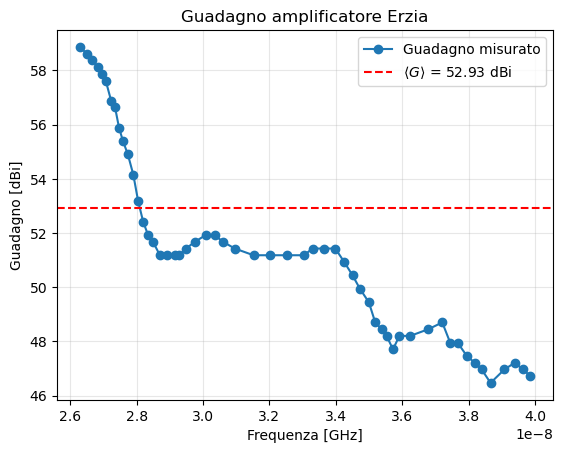

<Figure size 640x480 with 0 Axes>

In [3]:
import matplotlib.pyplot as plt

G_erzia_avg_dBi = 10*np.log10(G_erzia_avg)

fig, ax = plt.subplots()
ax.plot(freq_gain/1e9, G_erzia_dbi, "o-", label="Guadagno misurato")
ax.axhline(G_erzia_avg_dBi, color="r", linestyle="--", label=f"$\\langle G \\rangle$ = {G_erzia_avg_dBi:.2f} dBi")
ax.set_xlabel("Frequenza [GHz]")
ax.set_ylabel("Guadagno [dBi]")
ax.set_title("Guadagno amplificatore Erzia")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()
plt.savefig("gain_erzia_amplifier.pdf")

### Temperatura di rumore dell'amplificatore
$T_N(\nu)=T_0\,(F(\nu)-1)$, con $T_0$ fissato a 298 K. Gli errori legati alla temperatura di riferimento non sono inclusi; resta solo l'incertezza sulla noise figure $\sigma_{N}$.


In [4]:
# Temperatura di riferimento fissata a 298 K
T_erzia = 298.0

noise_data = np.loadtxt("noise_erzia_data.csv", delimiter=",", skiprows=1)
noise_data = noise_data[np.argsort(noise_data[:,0])]
freq_noise = noise_data[:,0]*1e9
N_erzia_dbi = noise_data[:,1]
N_erzia = 10**(N_erzia_dbi/10)


### Confronto media semplice e media integrale


In [5]:
TN_erzia = T_erzia*(N_erzia - 1)
TN_erzia_avg = np.mean(TN_erzia)
print(f"TN media semplice = {TN_erzia_avg:.2f} K")


TN media semplice = 279.87 K


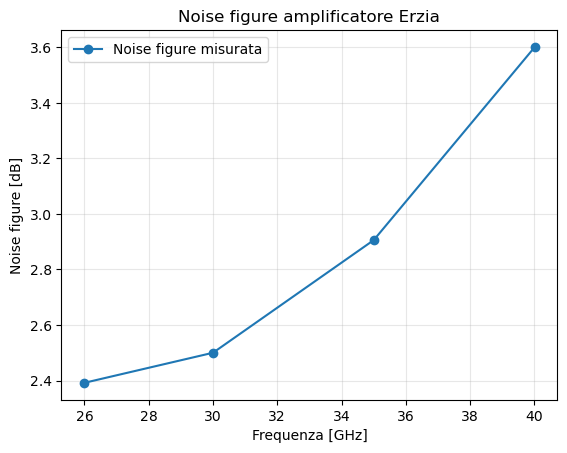

In [6]:
# confronto dei punti della noise figure
fig, ax = plt.subplots()
ax.plot(freq_noise/1e9, N_erzia_dbi, "o-", label="Noise figure misurata")
ax.set_xlabel("Frequenza [GHz]")
ax.set_ylabel("Noise figure [dB]")
ax.set_title("Noise figure amplificatore Erzia")
ax.grid(True, alpha=0.3)
ax.legend()
plt.savefig("noise_erzia_amplifier.pdf")
plt.show()


### Banda del sistema
Confrontiamo la frequenza di cuttoff della guida WR28, $f_{cut} = 21.077 GHz$, abbiamo una banda passante del filtro che è compresa tra $26.5 GHz - 40.0 GHz$ che ci da una banda passante di $\Delta \nu = 13.5 GHz$, essendo il bordo inferiore della banda passante del filtro maggiore della frequenza di cutoff sarà la banda del filtro da inserire nella formula.

In [7]:
delta_nu = 13.5e9 # banda passante del filtro (26.5 - 40.0 GHz)

### Temperatura di antenna
La temperatura di antenna è la convoluzione della temperatura di brillanza per il pattern normalizzato legato al sistema di ricezione:
$$
T_A = \frac{\int T_B(\theta,\Phi) P_N(\theta, \Phi) d \theta d \Phi}{\int P_N(\theta, \Phi)d \theta d \Phi}
$$
approssimiamo la $T_B(\theta, \Phi)$ come uniforme e uguale a quello termico, nel caso del sole, $T_B = 5770 K$ per un angolo $\theta = 0.5˚$.
Per l'angolo $\Phi $ integriamo ed essendo costante esce un coefficiente $2\pi$ che si semplifica con la normalizzazione a denominatore nella formula della $T_A$.

Calcoliamo due differenti temprature di antenna una sfruttando tutta l'apertura del telescopio, come se il feed horn non esistesse e la seconda tenendo condo delle dimensioni fisiche del feed horn e della sola luce che lo illumina.

La forma del pattern normalizzato viene presa come una Gaussiana, non vogliamo una tophat per non fare un'approssimazione troppo grossolana:
$$P(\theta, \Phi) = e^{\frac{-\theta^2}{2 \sigma^2}}$$
prendendo una $\theta_{FWHM} = \frac{\lambda}{D}$ vogliamo convertire questa quantità di scala come una larghezza della gaussiana conoscendo la relazione $\theta_{FWHM} = 2 \sqrt{2 \ln 2} \sigma$

Per la seconda configurazione con il feed horn, vediamo come l'apertura della antenna vede lo specchio, non occuperà litero diametro dello specchio ma una sua frazione, che ci darà un nuovo angolo.


In [8]:
import numpy as np
from scipy.constants import c, h, Boltzmann
from scipy.integrate import quad, dblquad

frequency = 30e9
wavelength = c/frequency
d_mirror = 1.473        # diametro primario [m]
focal_distance = 2.687  # focale equivalente [m]
d_horn = 0.0584         # diametro feed horn [m]

sun_half_angle = 0.25*np.pi/180   # raggio angolare del Sole [rad]
T_sun = 5770
x = h*frequency/(Boltzmann*T_sun)
T_b = x/np.expm1(x)*T_sun         # Planck, ~5769 K a 30 GHz

# --- porzione di primario illuminata dal feed horn ---
theta_horn = 1.22*wavelength/d_horn           # semi-angolo del primo nullo del horn
D_ill = 2*focal_distance*theta_horn           # diametro illuminato
D_eff = min(D_ill, d_mirror)                  # non puo' superare il primario

theta_sky = 1.02*wavelength/D_eff             # FWHM
sigma_horn = theta_sky/(2*np.sqrt(2*np.log(2)))

# --- frazione di potenza nel disco solare (beam gaussiano circolare) ---
# forma chiusa (approssimazione sin(theta) ~ theta)
frac_closed = 1 - np.exp(-sun_half_angle**2/(2*sigma_horn**2))

def P_N_exact(theta, sigma):
    # beam gaussiano pesato con l'elemento di angolo solido esatto
    return np.exp(-theta**2/(2*sigma**2))*np.sin(theta)

theta_max = 10*sigma_horn   # oltre questo il beam e' trascurabile

# 1) integrale 1D con sin(theta) esatto (il 2*pi di phi si semplifica)
num, _ = quad(P_N_exact, 0, sun_half_angle, args=(sigma_horn,))
den, _ = quad(P_N_exact, 0, theta_max, args=(sigma_horn,))
frac_quad = num/den

# 2) integrale bidimensionale vero (theta, phi) con dblquad
def integrand(phi, theta, sigma):
    # dblquad vuole f(y, x): y=phi (interno), x=theta (esterno)
    return np.exp(-theta**2/(2*sigma**2))*np.sin(theta)

num2, _ = dblquad(integrand, 0, sun_half_angle,
                  lambda th: 0, lambda th: 2*np.pi, args=(sigma_horn,))
den2, _ = dblquad(integrand, 0, theta_max,
                  lambda th: 0, lambda th: 2*np.pi, args=(sigma_horn,))
frac_2d = num2/den2

T_A_horn = T_b*frac_2d   # usa l'integrale 2D esatto

print("### ANTENNA TEMPERATURE ###")
print(f"T_b a 30 GHz: {T_b:.1f} K")
print(f"wavelength: {wavelength:.5f} m")
print(f"theta horn (primo nullo): {theta_horn:.4f} rad")
print(f"D_ill: {D_ill:.3f} m, D_eff: {D_eff:.3f} m")
print(f"FWHM sky: {theta_sky:.5f} rad = {np.degrees(theta_sky):.3f} deg")
print(f"sigma: {sigma_horn:.5f} rad = {np.degrees(sigma_horn):.3f} deg")
print(f"frazione (forma chiusa, approx): {frac_closed:.6f}")
print(f"frazione (quad, sin esatto):     {frac_quad:.6f}")
print(f"frazione (dblquad 2D):           {frac_2d:.6f}")
print(f"T_A horn: {T_A_horn:.0f} K")

### ANTENNA TEMPERATURE ###
T_b a 30 GHz: 5769.3 K
wavelength: 0.00999 m
theta horn (primo nullo): 0.2088 rad
D_ill: 1.122 m, D_eff: 1.122 m
FWHM sky: 0.00909 rad = 0.521 deg
sigma: 0.00386 rad = 0.221 deg
frazione (forma chiusa, approx): 0.472419
frazione (quad, sin esatto):     0.472421
frazione (dblquad 2D):           0.472421
T_A horn: 2726 K


## Risultati finali
Per le due configurazioni dell'antenna (mirror e horn) integriamo il guadagno e la temperatura di rumore punto per punto sulla banda dei dati di guadagno:
$$P = k_B\int_{\nu_{min}}^{\nu_{max}}G(\nu)[T_A+T_N(\nu)]\,d\nu.$$
La temperatura di antenna resta quella stimata a 30 GHz. La banda nominale del filtro è 26.5–40 GHz; l'integrale usa gli estremi effettivamente disponibili nei dati.

Nella potenza finale si usa il guadagno di catena amplificatore + filtro $G_{tot,lin}=\langle G_{Erzia,lin}\rangle\,G_{filtro,lin}$ e la temperatura di rumore efficace $T_{N,eff}$ (che include già il contributo del filtro, formula di Friis):
$$
P = k_B\,G_{tot,lin}\,\Delta\nu\,(T_A+T_{N,eff}).
$$


### Filtro dopo l'amplificatore (effetto sulla temperatura di rumore)
Inseriamo un filtro in uscita all'amplificatore con i seguenti parametri (datasheet):

| Parametro | Valore |
|---|---|
| Banda passante $\Delta\nu$ | 26 − 40 GHz |
| Attenuazione di inserzione $IL$ (a 30 GHz) | −0.14 dB |
| Ritorno $RL$ (input min) | −23 dB |

Per un componente con attenuazione di inserzione definita da $L=P_{in}/P_{out}$, il guadagno di potenza in dB è $IL_{dB}=10\log_{10}L$. 
Tenendo conto del disadattamento in ingresso (coefficiente di riflessione legato a $RL$), il fattore di potenza effettivo del filtro può essere espresso come:

$$
\rho = 10^{\frac{RL_{dB}}{10}}, \qquad G_{filtro}=\frac{1-\rho}{L}, \qquad G_{filtro,dB}=10\log_{10}\left(\frac{1-\rho}{L}\right).
$$

Con $RL_{dB}<0$, $\rho=|\Gamma_{in}|^2$. Per un filtro passivo alla temperatura fisica $T_f$ con fattore di attenuazione $L\ge1$ e $G_f=1/L$, la sua temperatura di rumore equivalente è $T_f = T_{phy}(L-1)$. Posto dopo l'amplificatore con guadagno $G_{amp}$ e temperatura di rumore $T_N^{(amp)}$, la formula di Friis dà

$$
T_{N,eff}=T_N^{(amp)} + \frac{T_f}{G_{amp}}\,.
$$

Si assume $T_{phy}\approx T_0=298\,\text{K}$.


In [9]:
TN_erzia = T_erzia*(N_erzia - 1)
TN_erzia_avg = np.mean(TN_erzia)

# Parametri del filtro e temperatura di rumore equivalente
IL_dB = -0.14
RL_dB = -23.0
L_filt = 10**(-IL_dB/10)
rho_filt = 10**(RL_dB/10)
Gf_lin = (1 - rho_filt)/L_filt
Gf_dB = 10*np.log10(Gf_lin)
T_filt = T_erzia*(L_filt - 1)
T_N_eff = TN_erzia_avg + T_filt/G_erzia_avg
print("### PARAMETRI E RISULTATI DEL FILTRO ###")
print(f"IL = {IL_dB:.3f} dB")
print(f"RL = {RL_dB:.3f} dB")
print(f"T_fisica = {T_erzia:.2f} K")
print(f"L_filt = {L_filt:.6f} (attenuazione lineare)")
print(f"rho_filt = {rho_filt:.6f} (frazione di potenza riflessa)")
print(f"Gf_lin = {Gf_lin:.6f}, Gf_dB = {Gf_dB:.3f} dB")
print(f"TN_erzia_avg = {TN_erzia_avg:.6f} K")
print(f"G_erzia_avg = {G_erzia_avg:.3f} ({10*np.log10(G_erzia_avg):.3f} dB)")
print(f"T_filt/G_erzia_avg = {T_filt/G_erzia_avg:.6e} K (contributo del filtro riferito all'ingresso)")
print(f"T_N_eff = {T_N_eff:.6f} K")
print(f"T_filt = {T_filt:.3f} K")

# Guadagno totale della catena amplificatore + filtro
G_tot_lin = G_erzia_avg * Gf_lin
G_tot_dB = 10*np.log10(G_tot_lin)
print(f"G_tot = {G_tot_lin:.3f} ({G_tot_dB:.3f} dB)")


### PARAMETRI E RISULTATI DEL FILTRO ###
IL = -0.140 dB
RL = -23.000 dB
T_fisica = 298.00 K
L_filt = 1.032761 (attenuazione lineare)
rho_filt = 0.005012 (frazione di potenza riflessa)
Gf_lin = 0.963425, Gf_dB = -0.162 dB
TN_erzia_avg = 279.873072 K
G_erzia_avg = 196476.640 (52.933 dB)
T_filt/G_erzia_avg = 4.968987e-05 K (contributo del filtro riferito all'ingresso)
T_N_eff = 279.873121 K
T_filt = 9.763 K
G_tot = 189290.501 (52.771 dB)


### Guadagno totale del sistema
Il guadagno totale in cascata è il prodotto dei guadagni lineari dei singoli stadi:

$$
G_{tot,lin} = G_{Erzia,lin} \cdot G_{filtro,lin}, \qquad G_{tot,dB} = G_{Erzia,dB} + G_{filtro,dB}\,.
$$

Poiché usiamo il guadagno medio dell'amplificatore sulla banda, calcoliamo anche il guadagno totale medio in forma lineare:

$$
\langle G_{tot,lin} \rangle = \langle G_{Erzia,lin} \rangle \cdot G_{filtro,lin}\,.
$$


In [10]:
# Riepilogo dei guadagni calcolati nella cella delle temperature di rumore

print("### GUADAGNO TOTALE SISTEMA ###")
print(f"⟨G_Erzia,lin⟩ = {G_erzia_avg:.3f} ({10*np.log10(G_erzia_avg):.3f} dB)")
print(f"G_filtro,lin   = {Gf_lin:.6f} ({Gf_dB:.3f} dB)")
print(f"⟨G_tot,lin⟩   = {G_tot_lin:.3f} ({G_tot_dB:.3f} dB)")


### GUADAGNO TOTALE SISTEMA ###
⟨G_Erzia,lin⟩ = 196476.640 (52.933 dB)
G_filtro,lin   = 0.963425 (-0.162 dB)
⟨G_tot,lin⟩   = 189290.501 (52.771 dB)


In [12]:
T_N_use = T_N_eff if 'T_N_eff' in globals() else TN_erzia_avg
#P_mirror_erzia = Boltzmann * G_erzia_avg * delta_nu * (T_A_mirror + T_N_use)
P_horn_erzia = Boltzmann * G_erzia_avg * delta_nu * (T_A_horn + T_N_use)
#print(f"P_mirror_erzia = {P_mirror_erzia:.6e} W")
print(f"P_horn_erzia   = {P_horn_erzia:.6e} W")

# Conversione in dBm: P[dBm] = 10*log10(P[W]/1e-3)
P_horn_erzia_dBm = 10*np.log10(P_horn_erzia/1e-3)
print(f"P_horn_erzia   = {P_horn_erzia_dBm:.3f} dBm")

# Catena completa: amplificatore + filtro (guadagno totale in cascata)
G_tot_use = G_tot_lin if 'G_tot_lin' in globals() else G_erzia_avg*(1 - rho_filt)/L_filt
P_horn_filter = Boltzmann * G_tot_use * delta_nu * (T_A_horn + T_N_use)
P_horn_filter_dBm = 10*np.log10(P_horn_filter/1e-3)
print(f"P_horn_filter  = {P_horn_filter:.6e} W")
print(f"P_horn_filter  = {P_horn_filter_dBm:.3f} dBm")


P_horn_erzia   = 1.100603e-04 W
P_horn_erzia   = -9.584 dBm
P_horn_filter  = 1.060348e-04 W
P_horn_filter  = -9.746 dBm
